# Error analysis: 50 mistakes, read one by one

The chosen model (TF-IDF 1-3 n-grams + logistic regression) gets 1,304 of the 20,000 validation reviews wrong. 50 of them were drawn at random (seed 7, `reviews.errors.sample_mistakes`) and each was read and given one cause. The labels are in `reports/error_labels.csv`: row numbers, scores and a short note, no review text.

One reader, one pass, so the categories are a judgement. Where a review fitted two, it got the one that best explains why the model went wrong.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("REVIEWS_DATA_DIR", "../data")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from reviews import errors
from reviews.compare import load
from reviews.model_store import load_model

grams = json.loads(Path("../reports/ngrams.json").read_text())
model = load_model(Path("../models/ngrams-best"), grams["winner_sha256"]).model
val_x, val_y = load("validation")
y = val_y.to_numpy()
prob = model.predict_proba(val_x)[:, 1]
pred = (prob >= 0.5).astype(int)
int((pred != y).sum())

1304

The labelled rows must be exactly the seeded sample, scored by this model:

In [2]:
labels = errors.load_labels("../reports/error_labels.csv")
rows = errors.sample_mistakes(y, prob)
assert labels["row"].tolist() == rows.tolist()
assert np.allclose(labels["prob_positive"], prob[rows], atol=0.006)
"labels match the sample"

'labels match the sample'

## Where the mistakes are

In [3]:
wrong = pred != y
{
    "negative called positive": int((wrong & (y == 0)).sum()),
    "positive called negative": int((wrong & (y == 1)).sum()),
    "confident mistakes (score < 0.1 or > 0.9)": int((wrong & ((prob < 0.1) | (prob > 0.9))).sum()),
    "near the line (0.4-0.6)": int((wrong & (prob > 0.4) & (prob < 0.6)).sum()),
}

{'negative called positive': 630,
 'positive called negative': 674,
 'confident mistakes (score < 0.1 or > 0.9)': 226,
 'near the line (0.4-0.6)': 348}

## Causes

In [4]:
def wilson(k, n, z=1.96):
    """95% interval for a share; 50 labels leave wide intervals."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return round(centre - half, 2), round(centre + half, 2)


counts = labels["cause"].value_counts()
table = pd.DataFrame(
    {
        "mistakes": counts,
        "share": (counts / len(labels)).round(2),
        "95%": [wilson(k, len(labels)) for k in counts],
        "meaning": [errors.CAUSES[c] for c in counts.index],
    }
)
table

,mistakes,share,95%,meaning
cause,,,,
mixed,16,0.32,"(0.21, 0.46)",Mixed or lukewarm: praise and complaint in the...
elsewhere,15,0.30,"(0.19, 0.44)",Praise or blame aimed at something else: anoth...
wording,10,0.20,"(0.11, 0.33)","Opinion without sentiment words, or wording th..."
no opinion,3,0.06,"(0.02, 0.16)","No opinion about the product: news, politics, ..."
sarcasm,3,0.06,"(0.02, 0.16)",Sarcasm or irony
label,2,0.04,"(0.01, 0.13)",The label contradicts the text
language,1,0.02,"(0.0, 0.1)",Not English


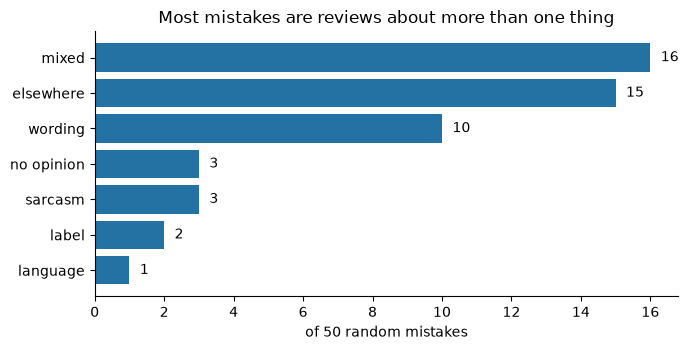

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(counts.index[::-1], counts.to_numpy()[::-1], color="#2471a3")
for i, v in enumerate(counts.to_numpy()[::-1]):
    ax.text(v + 0.3, i, str(v), va="center")
ax.set_xlabel("of 50 random mistakes")
ax.set_title("Most mistakes are reviews about more than one thing")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/error_causes.png", dpi=150)

In [6]:
pd.crosstab(labels["cause"], labels["true"].map({0: "true negative", 1: "true positive"}))

true,true negative,true positive
cause,,
elsewhere,11,4
label,2,0
language,1,0
mixed,8,8
no opinion,2,1
sarcasm,3,0
wording,2,8


## What this says

- **About 6 in 10 mistakes (31 of 50) are reviews about more than one thing.** Either praise and complaint are mixed (16), or the strong words are about something else: the previous edition, a rival product, the seller, the shipping (15). A bag of n-grams adds up every sentiment word in the review, whoever it's aimed at. Fixing this needs a model that knows *what* each opinion is about (aspect-based sentiment), not more n-grams.
- **Wording that misleads: 10.** Reviews that are positive but about a negative topic (insomnia, cancer, tyrants), praise through negations ("no creases"), poetic or broken English. Sentence embeddings (day 9) may help with some of these.
- **Label noise is small: 2 of 50 (4%, 1-13%).** Day 6's most confident mistake was a mislabelled review, but that's rare in a random sample. So label noise isn't what holds the score at 93.5%; most of the remaining 6.5% is the model's.
- **The causes split by direction** (crosstab above). Praise aimed elsewhere is mostly in negative reviews (11 of 15): a complaint that praises the old edition. Misleading wording is mostly in positive reviews (8 of 10): a happy review about a grim topic. Sarcasm is all negative (3 of 3).
- **Sarcasm 3, no product opinion 3, not English 1.** Small, as expected.
- With 50 labels, any share here is uncertain by up to ±13 points (the 95% column). The ranking of the top three causes is more reliable than their exact sizes.